In [2]:
import pandas as pd
import numpy as np
import subprocess
from collections import Counter
import gc
import matplotlib.pyplot as plt

In [3]:
from sklearn.cluster import KMeans
from tqdm import tqdm
from scipy.spatial import KDTree

# Major cell type niche

In [ ]:
sample_list_st = [
    "P1","P2","P3","P4","P5","P6","P7","P8","P9","P10","P11","P12","P13","P14","P15","P16","P26","P27","P30","P32","P33","P34","P35","P36","P37","P38","P39",
    "P40_1","P40_2","P42","P43_1","P43_2","P44","P45","P46","P47","P48","P49"
]

In [ ]:
path = "E:/Projects/BRCA/results/ST/Niche2607/"

In [ ]:
for spID in sample_list_st:
    print(spID)
    path_sp = path + spID + "/"
    celltype_file = path_sp + "celltype_" + spID + "_for_niche.csv"
    coord_file = path_sp +"coord_" + spID + ".csv"
    r = path_sp + "wanted_r.txt"
    output_file = path_sp + spID + "_neighborhood_matrix.csv"
    subprocess.run(["python","D:/Projects/Breast Cancer/codes/ST/14_Neighbor_population.py", "--celltype",celltype_file,"--coord",coord_file,"-r",r,"--output",output_file])

In [5]:
celltypes = ["bin","Adipocytes","B","Basal","DC","Endothelial","Epithelial","Fibroblasts","Macrophages","Mast","Pericytes","Plasma","T"]
neighbor_matrix = pd.DataFrame(columns=celltypes)

In [ ]:
for spID in sample_list_st:
    path_sp = path + spID + "/"
    matrix_file = path_sp + spID + "_neighborhood_matrix.csv"
    matrix_sp = pd.read_csv(matrix_file)
    print(spID)
    print(matrix_sp.isna().any().any())
    print(matrix_sp.shape)
    neighbor_matrix = pd.concat([neighbor_matrix, matrix_sp], ignore_index=True)

In [10]:
neighbor_matrix.set_index('bin', inplace=True)

In [13]:
neighbor_matrix = neighbor_matrix.fillna(0)

In [15]:
inertia_list = []
K_range = range(6, 30)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(neighbor_matrix)  # data contains the input data with nonnumeric columns removed
    inertia_list.append(km.inertia_)

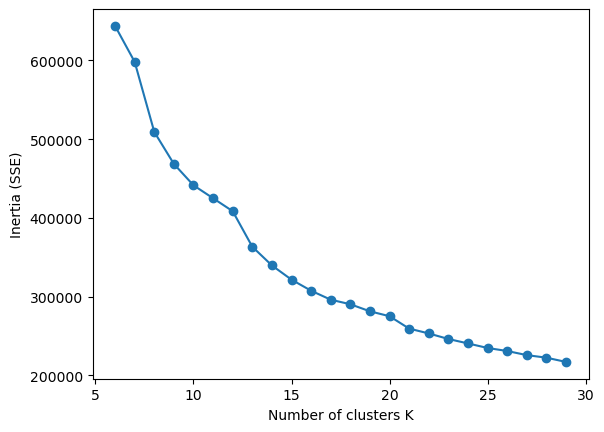

In [16]:
plt.plot(K_range, inertia_list, marker='o')
plt.xlabel('Number of clusters K')
plt.ylabel('Inertia (SSE)')
plt.show()

In [ ]:
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

fig, ax = plt.subplots(figsize=(3.5/2.54, 3.5/2.54))

ax.plot(K_range, inertia_list, marker='o', markersize=1.6, linewidth=1)

ax.set_xlabel('Number of clusters K', fontsize=5, fontname='Arial')
ax.set_ylabel('Inertia (SSE)', fontsize=5, fontname='Arial')

ax.tick_params(axis='both', which='major', labelsize=4)

for spine in ax.spines.values():
    spine.set_linewidth(0.5)
ax.tick_params(width=0.5, length=2)

output_pdf_path = "E:/Projects/BRCA/results/ST/Niche2607/K_selection_elbow_method.pdf"

plt.savefig(output_pdf_path, format='pdf', bbox_inches='tight', pad_inches=0.05, dpi=300)
plt.close()

print(f"PDF successfully saved to: {output_pdf_path}")

PDF successfully saved to: E:/Projects/BRCA/results/ST/Niche2607/K_selection_elbow_method.pdf


In [17]:
from kneed import KneeLocator

In [ ]:
kl = KneeLocator(K_range, inertia_list, curve='convex', direction='decreasing')

print(f"Calculated optimal number of clusters: {kl.elbow}")

In [63]:
kmeans = KMeans(n_clusters=14, random_state=32)

In [64]:
cluster = kmeans.fit_predict(neighbor_matrix)

In [65]:
neighbor_cluster = neighbor_matrix
neighbor_cluster['cluster'] = cluster

In [67]:
neighbor_cluster['cluster'] = neighbor_cluster['cluster'] + 1

In [68]:
neighbor_cluster['niche'] = "niche_" + neighbor_cluster['cluster'].astype(str)

In [69]:
Counter(neighbor_cluster['niche'])

Counter({'niche_1': 1401026,
         'niche_5': 1023118,
         'niche_2': 641484,
         'niche_12': 556574,
         'niche_14': 526089,
         'niche_8': 522166,
         'niche_4': 460028,
         'niche_10': 449756,
         'niche_9': 442664,
         'niche_13': 372081,
         'niche_3': 284243,
         'niche_7': 250229,
         'niche_6': 239162,
         'niche_11': 149182})

In [72]:
# Add cell type information for each cell
for spID in sample_list_st:
    path_sp = path + spID + "/"
    celltype_file = path_sp + "celltype_" + spID + ".csv"
    celltype_sp = pd.read_csv(celltype_file)
    celltype_sp = celltype_sp.loc[celltype_sp['bin'].isin(neighbor_cluster.index)]
    neighbor_cluster.loc[celltype_sp['bin'],'celltype'] = celltype_sp['celltype'].tolist()

In [73]:
Counter(neighbor_cluster['celltype'])

Counter({'Epithelial': 2876775,
         'Fibroblasts': 1219780,
         'Macrophages': 964969,
         'Endothelial': 787358,
         'Basal': 417900,
         'Plasma': 327766,
         'B': 255421,
         'T': 188360,
         'DC': 132836,
         'Pericytes': 100907,
         'Adipocytes': 25395,
         'Mast': 20335})

In [74]:
neighbor_cluster.to_csv("E:/Projects/BRCA/results/ST/Niche2607/neighborhood_cluster.csv")

In [75]:
df_mean = neighbor_cluster.groupby("cluster").mean(numeric_only=True)
df_prop = df_mean.div(df_mean.sum(axis=1), axis=0)

In [76]:
df_prop.to_csv("E:/Projects/BRCA/results/ST/Niche2607/niche_celltype_prop.csv")

# Perform DBSCAN clustering on macrophage niches

In [82]:
from sklearn.cluster import DBSCAN

In [84]:
sample_list_niche4 = [
  "ST564579",
  "ST1079003",
  "ST1020441_6",
  "ST1078903",
  "ST1020441_4",
  "ST1075108",
  "ST1094025",
  "ST1097658",
  "ST1072200",
  "ST1072814",
  "ST863656",
  "ST1022334",
  "ST1100356",
  "ST1068013",
  "ST1088776",
  "ST1073329"
]

In [79]:
niche_info = pd.read_csv("E:/Projects/BRCA/results/ST/Niche2607/neighborhood_cluster.csv")

In [85]:
def niche_4_dbscan(spID, r):
    sp_niche_info = niche_info.loc[niche_info['sample'] == spID]
    sp_niche_info = sp_niche_info.loc[sp_niche_info['niche'] == 'niche_4']
    sp_niche_info.set_index('bin', inplace=True)
    sp_coords = pd.read_csv(f"E:/Projects/BRCA/results/ST/Niche2607/{spID}/coord_{spID}.csv")
    sp_coords.set_index('bin', inplace=True)
    sp_coords = sp_coords.reindex(sp_niche_info.index)
    coords = sp_coords[['x', 'y']].values
    dbscan = DBSCAN(eps=r, min_samples=5, metric='euclidean')
    labels = dbscan.fit_predict(coords)
    sp_coords['cluster'] = labels
    print(Counter(labels))
    return sp_coords

In [87]:
for spID in sample_list_niche4:
    r80 = pd.read_csv(f'E:/Projects/BRCA/results/ST/Niche2607/{spID}/wanted_r.txt', sep="\t", header=None)
    r80 = r80.values[0,0]
    coords_dbscan = niche_4_dbscan(spID = spID, r = r80 / 80 * 300)
    coords_dbscan.to_csv(f'E:/Projects/BRCA/results/ST/Niche2607/{spID}/niche_4_dbscan_cluster.csv')

Counter({1: 90533, 4: 4046, 6: 3757, 0: 2201, 7: 634, 3: 93, 5: 68, 8: 66, 2: 24, 9: 5, -1: 3})
Counter({5: 65112, 3: 798, 4: 699, 1: 490, 2: 160, 6: 74, 7: 29, 0: 28, 8: 5, -1: 3})
Counter({2: 46860, 3: 6735, 6: 4739, 1: 2400, 4: 315, 5: 149, 9: 83, 0: 55, 8: 45, 7: 18, -1: 5})
Counter({9: 19390, 4: 8595, 0: 3832, 7: 3475, 15: 1661, 14: 953, 5: 657, 2: 645, 12: 522, 19: 273, 13: 272, 18: 229, 20: 103, 6: 91, 17: 62, 3: 54, 8: 32, 1: 28, 11: 20, 10: 16, -1: 8, 16: 7})
Counter({4: 16921, 0: 16329, 6: 1033, 5: 444, 1: 302, 3: 72, 2: 27, 7: 11, -1: 3})
Counter({6: 23364, 16: 4777, 3: 555, 7: 405, 4: 222, 15: 164, 0: 150, 13: 135, 11: 125, 10: 82, 1: 81, 8: 60, 2: 48, 5: 36, 14: 23, -1: 20, 12: 13, 9: 12})
Counter({0: 26527, 1: 898, 8: 849, 12: 475, 3: 405, 11: 264, 10: 128, 13: 115, 15: 106, 4: 89, 6: 84, 7: 75, 14: 24, 2: 12, 9: 10, 5: 9, -1: 7})
Counter({7: 10685, 8: 9315, 6: 526, 3: 148, 5: 88, 4: 36, 1: 27, 0: 8, 2: 7, -1: 4})
Counter({2: 11122, 0: 2642, 4: 830, 10: 631, 9: 559, 7: 12